# AML Risk Prioritization — A Guided Data Science Walkthrough

**Question:** Can we help AML investigators review a small number of account-days while capturing more positive synthetic labels than random review?

**What you will learn:** load an account-day dataset, use chronological splits, train a familiar baseline, compare XGBoost, choose a limited review queue, and evaluate it on untouched later data. Advanced techniques appear in optional appendices.

> **Important:** This is a synthetic-data portfolio study, not a bank deployment. A positive label is not proof of financial crime. Previously saved outputs come from the original notebook; this refactor has **not been rerun** against the original TSV exports.

**Reading path:** Steps 1–7 are the main story. Step 8 prepares Tableau output. Appendices A–C cover SHAP, cost scenarios, MLflow, and monitoring.


> **Reproduction status (October 2026):** The original and guided final XGBoost configurations were independently refit using the same data and XGBoost 3.1.3. Their full 494,707 prediction vectors matched exactly (max difference 0). Both selected **389** synthetic positives at capacity **2,747**. The supplied historical Tableau export selected **397**. Historical notebook output cells are preserved as original-run evidence, **not fresh verification**. The original XGBoost environment/model artifact is unavailable; do not conflate these versions. See `docs/REPRODUCIBILITY_AUDIT.md`.


### Which results should I cite?
- **Historical dashboard (verified from exported records):** 397/2,747 positives, ROC-AUC 0.85294841, PR-AUC 0.12311784.
- **Reproducible fresh XGBoost 3.1.3 model:** 389/2,747 positives, ROC-AUC 0.85225494, PR-AUC 0.12141259.
- Both are real calculations on the supplied synthetic dataset, but **they are not the same fitted model**. This notebook does not claim to reproduce the historical model artifact.
- The chronological split, nine predictor definitions, hyperparameters, and `random_state=42` are unchanged.


## Step 1 — Load the account-day dataset

**Question:** What does each row represent? The SQL export has one row per account per day. Check the date range, missing values, and positive-label frequency before modeling.


In [ ]:
# Optional: mount Google Drive when working in Colab.
# Skip this cell when using local files.
try:
    from google.colab import drive
except ImportError:
    print("Not running in Colab; using local files.")
else:
    drive.mount("/content/drive")


Mounted at /content/drive


In [ ]:
import numpy as np

In [ ]:
import pandas as pd

from pathlib import Path

# Set this path to your original SQL export before running.
file_path = Path("data/aml_modeling_dev.tsv")
if not file_path.exists():
    raise FileNotFoundError(
        f"Missing {file_path}. Download or export the original TSV and update file_path."
    )

dev = pd.read_csv(file_path, sep="\t")

print("Shape:", dev.shape)
print("\nColumns:")
print(dev.columns.tolist())

print("\nDate range:")
print(dev["activity_date"].min(), "to", dev["activity_date"].max())

print("\nTarget distribution:")
print(dev["has_laundering_tx"].value_counts(dropna=False))

print("\nTarget rate:")
print(dev["has_laundering_tx"].mean())

print("\nNull counts:")
print(dev.isna().sum())

Shape: (2479354, 13)

Columns:
['account_id', 'activity_date', 'transaction_count', 'outgoing_ratio', 'total_sent', 'total_received', 'avg_transaction_amount', 'max_transaction_amount', 'unique_counterparties', 'unique_banks', 'currency_diversity', 'rapid_transaction_ratio', 'has_laundering_tx']

Date range:
2022-09-01 to 2022-09-10

Target distribution:
has_laundering_tx
0    2472223
1       7131
Name: count, dtype: int64

Target rate:
0.002876152417121557

Null counts:
account_id                 0
activity_date              0
transaction_count          0
outgoing_ratio             0
total_sent                 0
total_received             0
avg_transaction_amount     0
max_transaction_amount     0
unique_counterparties      0
unique_banks               0
currency_diversity         0
rapid_transaction_ratio    0
has_laundering_tx          0
dtype: int64


## Step 2 — Separate the past from the future

**Decision:** Train on September 1–6, validate on September 7–8, and hold out September 9–10, 2022. Keeping later dates out of training makes the evaluation closer to a real forward-looking review process.


In [ ]:
dev["activity_date"] = pd.to_datetime(dev["activity_date"])

train = dev[
    dev["activity_date"].between("2022-09-01", "2022-09-06")
].copy()

validation = dev[
    dev["activity_date"].between("2022-09-07", "2022-09-08")
].copy()

test = dev[
    dev["activity_date"].between("2022-09-09", "2022-09-10")
].copy()

for name, df in {
    "TRAIN": train,
    "VALIDATION": validation,
    "TEST": test
}.items():
    print(
        name,
        "rows =", len(df),
        "| positives =", df["has_laundering_tx"].sum(),
        "| positive rate =", round(df["has_laundering_tx"].mean() * 100, 4), "%"
    )

TRAIN rows = 1534403 | positives = 4003 | positive rate = 0.2609 %
VALIDATION rows = 450244 | positives = 1629 | positive rate = 0.3618 %
TEST rows = 494707 | positives = 1499 | positive rate = 0.303 %


## Step 3 — Explore patterns using training data only

**Question:** Which activity features are skewed or differ across synthetic labels? We explore only the training period so test results cannot influence feature decisions.


In [ ]:
features = [
    "transaction_count",
    "outgoing_ratio",
    "total_sent",
    "total_received",
    "avg_transaction_amount",
    "max_transaction_amount",
    "unique_counterparties",
    "unique_banks",
    "currency_diversity",
    "rapid_transaction_ratio"
]

print("TRAIN SHAPE:", train.shape)
print("TRAIN POSITIVES:", train["has_laundering_tx"].sum())
print(
    "TRAIN POSITIVE RATE:",
    round(train["has_laundering_tx"].mean() * 100, 4),
    "%"
)

display(train[features].describe().T)

TRAIN SHAPE: (1534403, 13)
TRAIN POSITIVES: 4003
TRAIN POSITIVE RATE: 0.2609 %


,count,mean,std,min,25%,50%,75%,max
transaction_count,1534403.0,4.234769e+00,4.441526e+01,1.000000,2.00,3.0000,5.000000,2.690400e+04
outgoing_ratio,1534403.0,4.458230e-01,3.829809e-01,0.000000,0.00,0.5000,0.769200,1.000000e+00
total_sent,1534403.0,1.056357e+07,1.467285e+09,0.000000,0.00,560.2000,17087.600000,1.046302e+12
total_received,1534403.0,1.387158e+07,1.826442e+09,0.000000,16.15,2193.4600,29526.080000,1.046509e+12
avg_transaction_amount,1534403.0,4.332615e+06,8.857525e+08,0.000001,408.12,2686.1650,25293.554583,1.046302e+12
max_transaction_amount,1534403.0,1.536067e+07,1.677493e+09,0.000001,599.56,4763.3700,60059.810000,1.046302e+12
unique_counterparties,1534403.0,2.064220e+00,2.172901e+01,1.000000,1.00,1.0000,2.000000,1.307700e+04
unique_banks,1534403.0,1.939584e+00,2.261918e+00,1.000000,1.00,1.0000,2.000000,1.102000e+03
currency_diversity,1534403.0,1.014194e+00,1.206729e-01,1.000000,1.00,1.0000,1.000000,6.000000e+00
rapid_transaction_ratio,1534403.0,3.050830e-01,2.406785e-01,0.000000,0.00,0.3333,0.500000,1.000000e+00


In [ ]:
eda_summary = pd.DataFrame({
    "skewness": train[features].skew(),
    "median": train[features].median(),
    "p95": train[features].quantile(0.95),
    "p99": train[features].quantile(0.99),
    "max": train[features].max()
})

display(
    eda_summary
    .sort_values("skewness", ascending=False)
)

,skewness,median,p95,p99,max
avg_transaction_amount,1083.325747,2686.1650,1.114548e+06,1.868932e+07,1.046302e+12
total_sent,568.832563,560.2000,1.536885e+06,3.393325e+07,1.046302e+12
total_received,451.391517,2193.4600,2.005282e+06,4.471681e+07,1.046509e+12
max_transaction_amount,446.332373,4763.3700,3.468643e+06,6.788313e+07,1.046302e+12
transaction_count,415.507998,3.0000,1.100000e+01,1.800000e+01,2.690400e+04
unique_counterparties,411.579038,1.0000,5.000000e+00,8.000000e+00,1.307700e+04
unique_banks,167.651391,1.0000,5.000000e+00,7.000000e+00,1.102000e+03
currency_diversity,8.824395,1.0000,1.000000e+00,2.000000e+00,6.000000e+00
outgoing_ratio,0.175945,0.5000,1.000000e+00,1.000000e+00,1.000000e+00
rapid_transaction_ratio,-0.107051,0.3333,6.667000e-01,7.500000e-01,1.000000e+00


In [ ]:
class_profile = (
    train
    .groupby("has_laundering_tx")[features]
    .mean()
    .T
)

class_profile.columns = [
    "negative_mean",
    "positive_mean"
]

class_profile["positive_to_negative_ratio"] = (
    class_profile["positive_mean"]
    / class_profile["negative_mean"].replace(0, np.nan)
)

display(
    class_profile
    .sort_values(
        "positive_to_negative_ratio",
        ascending=False
    )
)

,negative_mean,positive_mean,positive_to_negative_ratio
total_sent,1.003703e+07,2.118665e+08,21.108477
unique_counterparties,1.979980e+00,3.427005e+01,17.308276
transaction_count,4.067865e+00,6.804447e+01,16.727318
max_transaction_amount,1.504847e+07,1.347180e+08,8.952267
avg_transaction_amount,4.268706e+06,2.876587e+07,6.738779
total_received,1.377325e+07,5.146653e+07,3.736703
unique_banks,1.929929e+00,5.630777e+00,2.917609
currency_diversity,1.013689e+00,1.207095e+00,1.190794
rapid_transaction_ratio,3.050432e-01,3.203061e-01,1.050035
outgoing_ratio,4.458497e-01,4.356010e-01,0.977013


In [ ]:
correlation_matrix = train[features].corr()

display(
    correlation_matrix.round(3)
)

,transaction_count,outgoing_ratio,total_sent,total_received,avg_transaction_amount,max_transaction_amount,unique_counterparties,unique_banks,currency_diversity,rapid_transaction_ratio
transaction_count,1.000,0.013,0.026,0.001,0.000,0.005,0.999,0.763,0.019,0.046
outgoing_ratio,0.013,1.000,0.005,-0.002,0.001,0.001,0.015,0.089,0.056,-0.129
total_sent,0.026,0.005,1.000,0.470,0.700,0.684,0.025,0.023,0.020,0.005
total_received,0.001,-0.002,0.470,1.000,0.188,0.820,0.002,0.009,0.015,0.006
avg_transaction_amount,0.000,0.001,0.700,0.188,1.000,0.652,0.000,0.001,0.004,0.000
max_transaction_amount,0.005,0.001,0.684,0.820,0.652,1.000,0.006,0.012,0.012,0.005
unique_counterparties,0.999,0.015,0.025,0.002,0.000,0.006,1.000,0.767,0.013,0.028
unique_banks,0.763,0.089,0.023,0.009,0.001,0.012,0.767,1.000,0.125,0.156
currency_diversity,0.019,0.056,0.020,0.015,0.004,0.012,0.013,0.125,1.000,0.146
rapid_transaction_ratio,0.046,-0.129,0.005,0.006,0.000,0.005,0.028,0.156,0.146,1.000


## Step 4 — Prepare the same features for every split

**Decision:** Apply the original fixed log transforms and feature list to training, validation, and test. Identifiers are retained for traceability, not used as model predictors.


In [ ]:
# Features requiring log1p transformation
log_features = [
    "transaction_count",
    "total_sent",
    "total_received",
    "avg_transaction_amount",
    "max_transaction_amount",
    "unique_banks"
]

# Stable bounded/untransformed features
direct_features = [
    "outgoing_ratio",
    "currency_diversity",
    "rapid_transaction_ratio"
]

def preprocess_features(df):
    X = pd.DataFrame(index=df.index)

    for col in log_features:
        X[f"log_{col}"] = np.log1p(df[col])

    for col in direct_features:
        X[col] = df[col]

    return X


X_train = preprocess_features(train)
X_val = preprocess_features(validation)
X_test = preprocess_features(test)

y_train = train["has_laundering_tx"].copy()
y_val = validation["has_laundering_tx"].copy()
y_test = test["has_laundering_tx"].copy()

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("\nFinal predictors:")
print(X_train.columns.tolist())

print("\nNulls:")
print(X_train.isna().sum())

print("\nInfinite values:")
print(np.isinf(X_train).sum())

X_train: (1534403, 9)
X_val: (450244, 9)
X_test: (494707, 9)

Final predictors:
['log_transaction_count', 'log_total_sent', 'log_total_received', 'log_avg_transaction_amount', 'log_max_transaction_amount', 'log_unique_banks', 'outgoing_ratio', 'currency_diversity', 'rapid_transaction_ratio']

Nulls:
log_transaction_count         0
log_total_sent                0
log_total_received            0
log_avg_transaction_amount    0
log_max_transaction_amount    0
log_unique_banks              0
outgoing_ratio                0
currency_diversity            0
rapid_transaction_ratio       0
dtype: int64

Infinite values:
log_transaction_count         0
log_total_sent                0
log_total_received            0
log_avg_transaction_amount    0
log_max_transaction_amount    0
log_unique_banks              0
outgoing_ratio                0
currency_diversity            0
rapid_transaction_ratio       0
dtype: int64


In [ ]:
transformed_summary = pd.DataFrame({
    "skewness": X_train.skew(),
    "median": X_train.median(),
    "p99": X_train.quantile(0.99),
    "max": X_train.max()
})

display(
    transformed_summary.sort_values(
        "skewness",
        ascending=False
    )
)

,skewness,median,p99,max
currency_diversity,8.824395,1.000000,2.000000,6.000000
log_unique_banks,1.219583,0.693147,2.079442,7.005789
log_transaction_count,0.635162,1.386294,2.944439,10.200067
log_total_sent,0.270979,6.330077,17.339906,27.676284
log_max_transaction_amount,0.181644,8.468921,18.033298,27.676284
outgoing_ratio,0.175945,0.500000,1.000000,1.000000
log_avg_transaction_amount,0.175934,7.896242,16.743463,27.676284
log_total_received,-0.045468,7.693691,17.615860,27.676481
rapid_transaction_ratio,-0.107051,0.333300,0.750000,1.000000


## Step 5 — Establish a simple baseline

**Question:** What happens if we start with logistic regression? First check ranking metrics; then observe why its default 0.50 cutoff would create an impractical queue.


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression training complete.")

Logistic Regression training complete.


In [ ]:
val_prob = logistic_model.predict_proba(X_val)[:, 1]

print("Validation ROC-AUC:",
      round(roc_auc_score(y_val, val_prob), 4))

print("Validation PR-AUC:",
      round(average_precision_score(y_val, val_prob), 4))

Validation ROC-AUC: 0.7995
Validation PR-AUC: 0.0378


In [ ]:
threshold = 0.50

val_pred = (val_prob >= threshold).astype(int)

precision = precision_score(y_val, val_pred)
recall = recall_score(y_val, val_pred)
f1 = f1_score(y_val, val_pred)

tn, fp, fn, tp = confusion_matrix(
    y_val,
    val_pred
).ravel()

print("Threshold:", threshold)
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1:", round(f1, 4))

print("\nConfusion Matrix")
print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

print("\nAlerts generated:", fp + tp)
print("Actual laundering-positive account-days:", tp + fn)

Threshold: 0.5
Precision: 0.0101
Recall: 0.7133
F1: 0.0199

Confusion Matrix
TN: 334434
FP: 114181
FN: 467
TP: 1162

Alerts generated: 115343
Actual laundering-positive account-days: 1629


### One reusable queue calculation

Instead of writing the same loop for logistic regression, XGBoost, and the final review policy, the small function below answers one question: **if investigators review the top *k* account-days, how many positive labels are in that queue?** It uses the same sorting, tie behavior, and formulas as the original notebook.

In [ ]:
def top_k_results(labels, scores, capacities):
    """Measure positive-label yield among the highest-scored rows."""
    ranking = pd.DataFrame({"actual": np.asarray(labels), "probability": scores})
    ranking = ranking.sort_values("probability", ascending=False).reset_index(drop=True)
    total_positives = ranking["actual"].sum()
    base_rate = ranking["actual"].mean()
    rows = []
    for k in capacities:
        selected = ranking.head(k)
        found = int(selected["actual"].sum())
        rows.append({
            "alerts_reviewed": k,
            "true_positives_found": found,
            "precision": found / k,
            "recall": found / total_positives,
            "lift_vs_random": (found / k) / base_rate,
            "threshold": selected["probability"].iloc[-1],
        })
    return pd.DataFrame(rows)

capacity_levels = [500, 1000, 2500, 5000, 10000, 25000]
capacity_results = top_k_results(y_val, val_prob, capacity_levels)
display(capacity_results.style.format({
    "precision": "{:.2%}", "recall": "{:.2%}",
    "lift_vs_random": "{:.1f}x", "threshold": "{:.4f}"
}))

## Step 6 — Compare a stronger model and choose queue capacity

**Decision:** Compare XGBoost with the baseline, tune using validation only, and select the original 2,500-alert validation policy. The repeated capacity tables are retained for auditability; they can be consolidated after rerunning a regression test.


In [ ]:
from xgboost import XGBClassifier

negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Negative observations:", negative_count)
print("Positive observations:", positive_count)
print("Scale positive weight:", round(scale_pos_weight, 2))

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,

    objective="binary:logistic",
    eval_metric="aucpr",

    scale_pos_weight=scale_pos_weight,

    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    verbose=False
)

print("XGBoost training complete.")

Negative observations: 1530400
Positive observations: 4003
Scale positive weight: 382.31
XGBoost training complete.


In [ ]:
xgb_val_prob = xgb_model.predict_proba(X_val)[:, 1]

xgb_roc_auc = roc_auc_score(
    y_val,
    xgb_val_prob
)

xgb_pr_auc = average_precision_score(
    y_val,
    xgb_val_prob
)

print(
    "XGBoost Validation ROC-AUC:",
    round(xgb_roc_auc, 4)
)

print(
    "XGBoost Validation PR-AUC:",
    round(xgb_pr_auc, 4)
)

XGBoost Validation ROC-AUC: 0.8465
XGBoost Validation PR-AUC: 0.1251


In [ ]:
xgb_capacity_results = top_k_results(y_val, xgb_val_prob, capacity_levels)
display(xgb_capacity_results.style.format({
    "precision": "{:.2%}", "recall": "{:.2%}",
    "lift_vs_random": "{:.1f}x", "threshold": "{:.4f}"
}))

In [ ]:
configs = [
    {"name": "baseline", "max_depth": 4, "learning_rate": 0.05, "n_estimators": 300},
    {"name": "shallower", "max_depth": 3, "learning_rate": 0.05, "n_estimators": 300},
    {"name": "slower_more_trees", "max_depth": 4, "learning_rate": 0.03, "n_estimators": 500},
    {"name": "deeper", "max_depth": 5, "learning_rate": 0.05, "n_estimators": 300}
]

tuning_results = []

for config in configs:

    model = XGBClassifier(
        n_estimators=config["n_estimators"],
        max_depth=config["max_depth"],
        learning_rate=config["learning_rate"],
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="aucpr",
        scale_pos_weight=scale_pos_weight,
        random_state=42,
        n_jobs=-1
    )

    model.fit(
        X_train,
        y_train,
        eval_set=[(X_val, y_val)],
        verbose=False
    )

    prob = model.predict_proba(X_val)[:, 1]

    ranking = pd.DataFrame({
        "actual": y_val.to_numpy(),
        "probability": prob
    }).sort_values("probability", ascending=False)

    top_500 = ranking.head(500)
    top_5000 = ranking.head(5000)

    tuning_results.append({
        "model": config["name"],
        "ROC_AUC": roc_auc_score(y_val, prob),
        "PR_AUC": average_precision_score(y_val, prob),
        "TP_at_500": int(top_500["actual"].sum()),
        "Precision_at_500": top_500["actual"].mean(),
        "TP_at_5000": int(top_5000["actual"].sum()),
        "Precision_at_5000": top_5000["actual"].mean()
    })

tuning_results = pd.DataFrame(tuning_results)

display(
    tuning_results.sort_values(
        "PR_AUC",
        ascending=False
    ).style.format({
        "ROC_AUC": "{:.4f}",
        "PR_AUC": "{:.4f}",
        "Precision_at_500": "{:.2%}",
        "Precision_at_5000": "{:.2%}"
    })
)

,model,ROC_AUC,PR_AUC,TP_at_500,Precision_at_500,TP_at_5000,Precision_at_5000
3,deeper,0.8457,0.1308,206,41.20%,465,9.30%
0,baseline,0.8465,0.1251,184,36.80%,462,9.24%
2,slower_more_trees,0.8474,0.1228,184,36.80%,469,9.38%
1,shallower,0.8438,0.1102,147,29.40%,453,9.06%


In [ ]:
from xgboost import XGBClassifier

final_xgb = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="aucpr",
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    n_jobs=-1
)

final_xgb.fit(X_train, y_train)

final_val_prob = final_xgb.predict_proba(X_val)[:, 1]

print("Final XGBoost trained.")

Final XGBoost trained.


In [ ]:
capacity_options = [500, 1000, 2500, 5000]
policy_results = top_k_results(y_val, final_val_prob, capacity_options).rename(columns={
    "alerts_reviewed": "alerts",
    "true_positives_found": "true_positives",
    "lift_vs_random": "lift",
})
policy_results["review_rate"] = policy_results["alerts"] / len(y_val)
policy_results["false_positives"] = policy_results["alerts"] - policy_results["true_positives"]
policy_results = policy_results[[
    "alerts", "review_rate", "true_positives", "false_positives",
    "precision", "recall", "lift", "threshold"
]]
display(policy_results.style.format({
    "review_rate": "{:.3%}", "precision": "{:.2%}",
    "recall": "{:.2%}", "lift": "{:.1f}x", "threshold": "{:.4f}"
}))

## Step 7 — Test the frozen decision

**Question:** With no further tuning, how many positive synthetic labels appear in the held-out queue? The original result is 2,747 selected out of 494,707 account-days, including 397 positives (14.45% precision; 26.48% recall; 47.7× lift).


In [ ]:
# Score untouched test population
test_prob = final_xgb.predict_proba(X_test)[:, 1]

# Overall ranking metrics
test_roc_auc = roc_auc_score(y_test, test_prob)
test_pr_auc = average_precision_score(y_test, test_prob)

# Frozen validation-derived operating policy
review_rate = 2500 / len(y_val)

test_capacity = round(
    len(y_test) * review_rate
)

test_ranking = pd.DataFrame({
    "actual": y_test.to_numpy(),
    "probability": test_prob
}).sort_values(
    "probability",
    ascending=False
).reset_index(drop=True)

reviewed = test_ranking.head(test_capacity)

tp = int(reviewed["actual"].sum())
fp = test_capacity - tp

total_test_positives = int(test_ranking["actual"].sum())

precision = tp / test_capacity
recall = tp / total_test_positives

test_base_rate = test_ranking["actual"].mean()
lift = precision / test_base_rate

threshold = reviewed["probability"].iloc[-1]

print("FINAL TEST RESULTS")
print("------------------")
print("ROC-AUC:", round(test_roc_auc, 4))
print("PR-AUC:", round(test_pr_auc, 4))

print("\nFrozen review rate:",
      round(review_rate * 100, 3), "%")

print("Test alerts reviewed:", test_capacity)
print("True positives:", tp)
print("False positives:", fp)

print("Precision:", round(precision * 100, 2), "%")
print("Recall:", round(recall * 100, 2), "%")
print("Lift vs random:", round(lift, 1), "x")
print("Test threshold:", round(threshold, 4))

FINAL TEST RESULTS
------------------
ROC-AUC: 0.8529
PR-AUC: 0.1231

Frozen review rate: 0.555 %
Test alerts reviewed: 2747
True positives: 397
False positives: 2350
Precision: 14.45 %
Recall: 26.48 %
Lift vs random: 47.7 x
Test threshold: 0.9034


## Step 8 — Prepare the investigator dashboard export

**Output:** Export test account-days, their frozen rankings, selection flags, and review outcomes. This is a presentation artifact; it must match the same held-out predictions.


### Before exporting: protect account-to-score alignment

A dashboard can show convincing but incorrect results if risk scores are attached to the wrong rows. The checks below ensure the model features, target labels, original test records, and predictions all refer to the **same account-days in the same order**.

In [ ]:
# Use the original test DataFrame in its model-scoring order.
# This protects against accidentally attaching predictions to different accounts.
assert X_test.index.equals(test.index), "Test features and records are out of order"
assert y_test.index.equals(test.index), "Test labels and records are out of order"
assert y_test.equals(test["has_laundering_tx"]), "Test labels do not match"
assert len(test_prob) == len(test), "Prediction count does not match test rows"
assert test["activity_date"].between("2022-09-09", "2022-09-10").all()
assert not test.index.has_duplicates, "Test row indices must be unique"

tableau_test = test.copy()
tableau_test["risk_score"] = test_prob
# 'first' preserves the original tie-handling rule.
tableau_test["risk_rank"] = (
    tableau_test["risk_score"].rank(method="first", ascending=False).astype(int)
)
print("Verified: test rows, labels, and prediction order align.")

In [ ]:
# Apply the validation-selected review rate; do not retune on test data.
review_rate = 2500 / len(y_val)
alert_capacity = round(len(tableau_test) * review_rate)
assert alert_capacity == test_capacity, "Dashboard capacity differs from test policy"

tableau_test["selected_for_review"] = (
    tableau_test["risk_rank"] <= alert_capacity
).astype(int)
tableau_test["model_outcome"] = np.select(
    [
        (tableau_test["selected_for_review"] == 1) & (tableau_test["has_laundering_tx"] == 1),
        (tableau_test["selected_for_review"] == 1) & (tableau_test["has_laundering_tx"] == 0),
        (tableau_test["selected_for_review"] == 0) & (tableau_test["has_laundering_tx"] == 1),
    ],
    ["True Positive", "False Positive", "False Negative"],
    default="True Negative",
)
assert int(((tableau_test["selected_for_review"] == 1) &
            (tableau_test["has_laundering_tx"] == 1)).sum()) == tp,     "Dashboard positive count differs from held-out test"
print("Exact review rate:", review_rate)
print("Alert capacity:", alert_capacity)
print(tableau_test["model_outcome"].value_counts())

In [ ]:
Path("outputs").mkdir(parents=True, exist_ok=True)

tableau_columns = [
    "account_id",
    "activity_date",
    "transaction_count",
    "outgoing_ratio",
    "total_sent",
    "total_received",
    "avg_transaction_amount",
    "max_transaction_amount",
    "unique_counterparties",
    "unique_banks",
    "currency_diversity",
    "rapid_transaction_ratio",
    "has_laundering_tx",
    "risk_score",
    "risk_rank",
    "selected_for_review",
    "model_outcome"
]

tableau_export = tableau_test[tableau_columns].copy()

output_path = (
    "outputs/"
    "aml_tableau_decision_data.csv"
)

tableau_export.to_csv(
    output_path,
    index=False
)

print("Exported:", output_path)
print("Shape:", tableau_export.shape)

Exported: /content/drive/MyDrive/AML_Portfolio/aml_tableau_decision_data.csv
Shape: (494707, 17)


## What this main analysis shows

The useful outcome is **a manageable, ranked investigation queue**, not a claim that the model can identify confirmed crimes. The queue-size policy was chosen on validation data and tested on a later period. All reported numbers above are inherited from the original run and should be checked again once the original TSV files are available.

The following appendices preserve the advanced analyses for reviewers who want to inspect them. They are not required to understand the main modeling decision.


## Appendix A — Explain the model (SHAP)

SHAP is an optional interpretation tool. These explanations describe the model’s predictions, not causal evidence.


In [ ]:
!pip -q install shap

import shap
import matplotlib.pyplot as plt

print("SHAP version:", shap.__version__)

In [ ]:
# Reproducible test sample
X_shap = X_test.sample(
    n=10000,
    random_state=42
)

explainer = shap.TreeExplainer(final_xgb)

shap_values = explainer(X_shap)

print("SHAP calculation complete.")
print("Sample size:", len(X_shap))

SHAP calculation complete.
Sample size: 10000


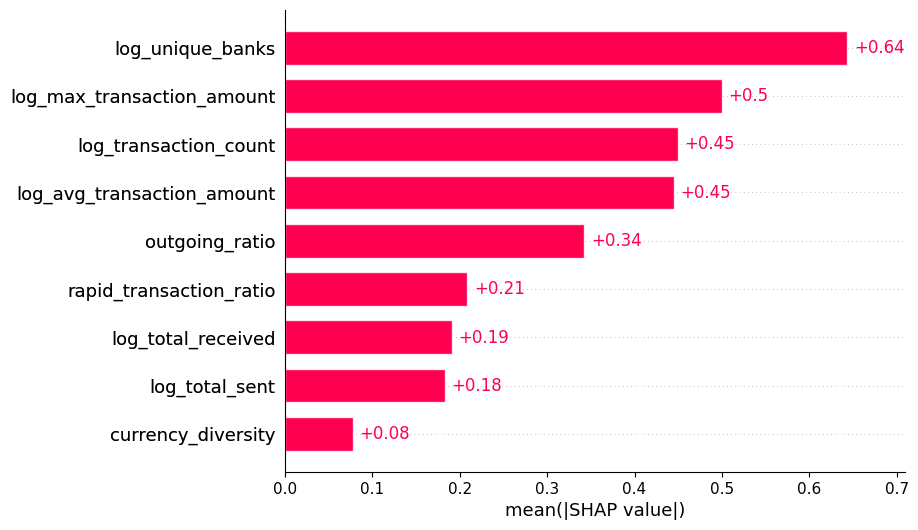

In [ ]:
shap.plots.bar(
    shap_values,
    max_display=9
)

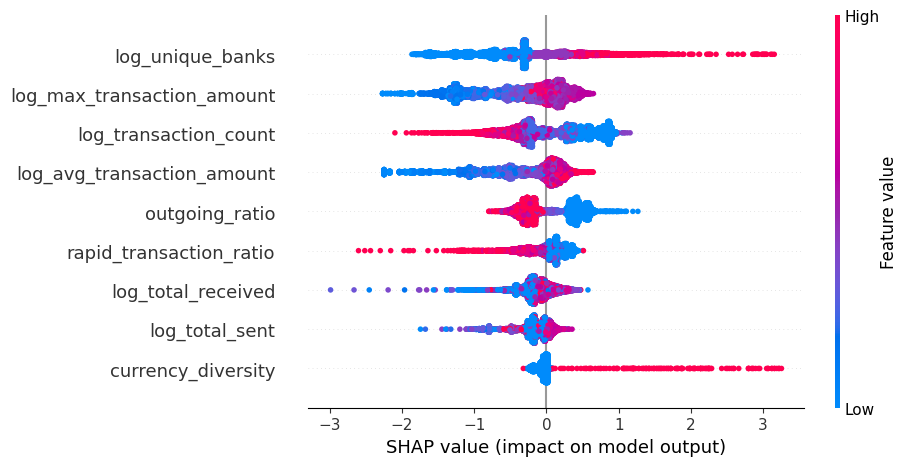

In [ ]:
shap.plots.beeswarm(
    shap_values,
    max_display=9
)

Predicted risk: 0.9948

Feature values:


,log_transaction_count,log_total_sent,log_total_received,log_avg_transaction_amount,log_max_transaction_amount,log_unique_banks,outgoing_ratio,currency_diversity,rapid_transaction_ratio
1338499,1.386294,14.081584,14.06253,13.666638,14.06253,1.098612,0.6667,2,0.6667


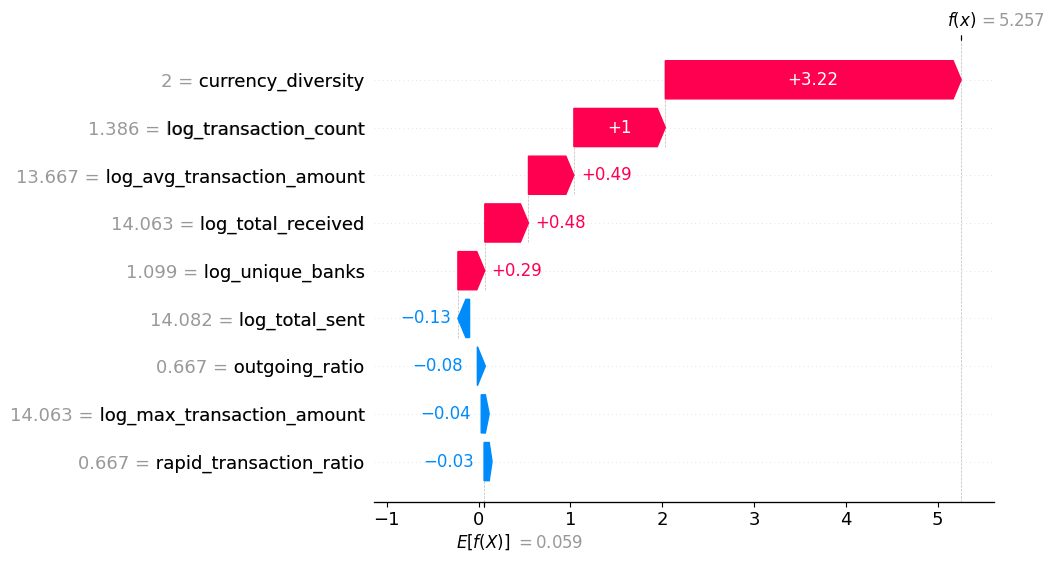

In [ ]:
# Highest-risk observation in our SHAP sample
sample_probabilities = final_xgb.predict_proba(X_shap)[:, 1]
highest_risk_position = np.argmax(sample_probabilities)

print(
    "Predicted risk:",
    round(sample_probabilities[highest_risk_position], 4)
)

print("\nFeature values:")
display(
    X_shap.iloc[[highest_risk_position]]
)

shap.plots.waterfall(
    shap_values[highest_risk_position],
    max_display=9
)

## Appendix B — Explore hypothetical costs and experiment tracking

These are optional sensitivity and recordkeeping exercises. Cost assumptions are illustrative, and the original MLflow metrics include manually logged values.


In [ ]:
# Wider capacity range so we can observe the economic tradeoff
capacity_options = [
    250,
    500,
    1000,
    2500,
    5000,
    10000,
    25000,
    50000
]

# Hypothetical relative cost of missing a positive case
fn_cost_ratios = [10, 25, 50, 100, 250]

# One unnecessary investigation = 1 cost unit
fp_cost = 1

ranking = pd.DataFrame({
    "actual": y_val.to_numpy(),
    "probability": final_val_prob
}).sort_values(
    "probability",
    ascending=False
).reset_index(drop=True)

total_positives = int(ranking["actual"].sum())

results = []

for capacity in capacity_options:

    reviewed = ranking.head(capacity)

    tp = int(reviewed["actual"].sum())
    fp = capacity - tp
    fn = total_positives - tp

    precision = tp / capacity
    recall = tp / total_positives

    row = {
        "alerts": capacity,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "precision": precision,
        "recall": recall
    }

    for fn_cost in fn_cost_ratios:

        total_cost = (
            fp * fp_cost
            + fn * fn_cost
        )

        row[f"cost_FN_{fn_cost}x"] = total_cost

    results.append(row)

cost_results = pd.DataFrame(results)

display(
    cost_results.style.format({
        "precision": "{:.2%}",
        "recall": "{:.2%}"
    })
)

,alerts,TP,FP,FN,precision,recall,cost_FN_10x,cost_FN_25x,cost_FN_50x,cost_FN_100x,cost_FN_250x
0,250,151,99,1478,60.40%,9.27%,14879,37049,73999,147899,369599
1,500,206,294,1423,41.20%,12.65%,14524,35869,71444,142594,356044
2,1000,255,745,1374,25.50%,15.65%,14485,35095,69445,138145,344245
3,2500,381,2119,1248,15.24%,23.39%,14599,33319,64519,126919,314119
4,5000,465,4535,1164,9.30%,28.55%,16175,33635,62735,120935,295535
5,10000,564,9436,1065,5.64%,34.62%,20086,36061,62686,115936,275686
6,25000,764,24236,865,3.06%,46.90%,32886,45861,67486,110736,240486
7,50000,953,49047,676,1.91%,58.50%,55807,65947,82847,116647,218047


In [ ]:
optimal_results = []

for fn_cost in fn_cost_ratios:

    cost_column = f"cost_FN_{fn_cost}x"

    best_index = cost_results[cost_column].idxmin()
    best = cost_results.loc[best_index]

    optimal_results.append({
        "FN_cost_ratio": f"{fn_cost}x",
        "optimal_alert_capacity": int(best["alerts"]),
        "true_positives": int(best["TP"]),
        "false_positives": int(best["FP"]),
        "false_negatives": int(best["FN"]),
        "precision": best["precision"],
        "recall": best["recall"],
        "minimum_cost_units": int(best[cost_column])
    })

optimal_policy = pd.DataFrame(optimal_results)

display(
    optimal_policy.style.format({
        "precision": "{:.2%}",
        "recall": "{:.2%}"
    })
)

,FN_cost_ratio,optimal_alert_capacity,true_positives,false_positives,false_negatives,precision,recall,minimum_cost_units
0,10x,1000,255,745,1374,25.50%,15.65%,14485
1,25x,2500,381,2119,1248,15.24%,23.39%,33319
2,50x,10000,564,9436,1065,5.64%,34.62%,62686
3,100x,25000,764,24236,865,3.06%,46.90%,110736
4,250x,50000,953,49047,676,1.91%,58.50%,218047


In [ ]:
!pip -q install mlflow

import mlflow
import mlflow.sklearn
import mlflow.xgboost

print("MLflow version:", mlflow.__version__)

In [ ]:
mlflow.set_experiment("AML_Risk_Model_Development")

2026/08/20 22:39:59 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/08/20 22:39:59 INFO mlflow.store.db.utils: Updating database tables
2026/08/20 22:40:02 INFO mlflow.tracking.fluent: Experiment with name 'AML_Risk_Model_Development' does not exist. Creating a new experiment.


<Experiment: artifact_location='/content/mlruns/1', creation_time=1787265602644, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1787265602644, lifecycle_stage='active', name='AML_Risk_Model_Development', tags={}, trace_location=None, workspace='default'>

In [ ]:
with mlflow.start_run(run_name="logistic_baseline"):

    mlflow.log_param("model_type", "LogisticRegression")
    mlflow.log_param("class_weight", "balanced")
    mlflow.log_param("feature_count", 9)

    mlflow.log_metric("validation_roc_auc", 0.7995)
    mlflow.log_metric("validation_pr_auc", 0.0378)

    mlflow.log_metric("precision_at_500", 0.0920)
    mlflow.log_metric("recall_at_500", 0.0282)
    mlflow.log_metric("lift_at_500", 25.4)

    mlflow.sklearn.log_model(
        logistic_model,
        name="model"
    )

In [ ]:
with mlflow.start_run(run_name="xgboost_final_depth5"):

    mlflow.log_param("model_type", "XGBoost")
    mlflow.log_param("n_estimators", 300)
    mlflow.log_param("max_depth", 5)
    mlflow.log_param("learning_rate", 0.05)
    mlflow.log_param("subsample", 0.8)
    mlflow.log_param("colsample_bytree", 0.8)
    mlflow.log_param("scale_pos_weight", scale_pos_weight)
    mlflow.log_param("feature_count", 9)

    mlflow.log_metric("validation_roc_auc", 0.8457)
    mlflow.log_metric("validation_pr_auc", 0.1308)

    mlflow.log_metric("precision_at_500", 0.4120)
    mlflow.log_metric("recall_at_500", 0.1265)

    mlflow.log_metric("primary_review_rate", 0.00555)
    mlflow.log_metric("primary_capacity_validation", 2500)

    mlflow.log_metric("test_roc_auc", 0.8529)
    mlflow.log_metric("test_pr_auc", 0.1231)
    mlflow.log_metric("test_precision", 0.1445)
    mlflow.log_metric("test_recall", 0.2648)
    mlflow.log_metric("test_lift", 47.7)

    mlflow.xgboost.log_model(
        final_xgb,
        name="model"
    )

In [ ]:
runs = mlflow.search_runs(
    experiment_names=["AML_Risk_Model_Development"]
)

display(
    runs[
        [
            "tags.mlflow.runName",
            "metrics.validation_roc_auc",
            "metrics.validation_pr_auc",
            "params.model_type",
            "params.max_depth"
        ]
    ]
)

,tags.mlflow.runName,metrics.validation_roc_auc,metrics.validation_pr_auc,params.model_type,params.max_depth
0,xgboost_final_depth5,0.8457,0.1308,XGBoost,5
1,logistic_baseline,0.7995,0.0378,LogisticRegression,None


## Appendix C — Monitor unusual later data

The later OOD population has 922 positives out of 923 observations. Treat it as a distribution-shift warning, not a normal test set.


In [ ]:
ood_path = Path("data/aml_modeling_ood.tsv")
if not ood_path.exists():
    raise FileNotFoundError(f"Missing {ood_path}; provide the original OOD TSV.")

ood = pd.read_csv(
    ood_path,
    sep="\t"
)

ood["activity_date"] = pd.to_datetime(
    ood["activity_date"]
)

print("OOD shape:", ood.shape)
print(
    "Date range:",
    ood["activity_date"].min(),
    "to",
    ood["activity_date"].max()
)

print("\nNulls:")
print(ood.isna().sum())

OOD shape: (923, 13)
Date range: 2022-09-11 00:00:00 to 2022-09-18 00:00:00

Nulls:
account_id                 0
activity_date              0
transaction_count          0
outgoing_ratio             0
total_sent                 0
total_received             0
avg_transaction_amount     0
max_transaction_amount     0
unique_counterparties      0
unique_banks               0
currency_diversity         0
rapid_transaction_ratio    0
has_laundering_tx          0
dtype: int64


In [ ]:
X_ood = preprocess_features(ood)
y_ood = ood["has_laundering_tx"].copy()

print("X_ood shape:", X_ood.shape)

print("\nColumns identical to training:",
      X_ood.columns.tolist() == X_train.columns.tolist())

print("\nNulls:")
print(X_ood.isna().sum())

print("\nInfinite values:")
print(np.isinf(X_ood).sum())

X_ood shape: (923, 9)

Columns identical to training: True

Nulls:
log_transaction_count         0
log_total_sent                0
log_total_received            0
log_avg_transaction_amount    0
log_max_transaction_amount    0
log_unique_banks              0
outgoing_ratio                0
currency_diversity            0
rapid_transaction_ratio       0
dtype: int64

Infinite values:
log_transaction_count         0
log_total_sent                0
log_total_received            0
log_avg_transaction_amount    0
log_max_transaction_amount    0
log_unique_banks              0
outgoing_ratio                0
currency_diversity            0
rapid_transaction_ratio       0
dtype: int64


In [ ]:
drift_summary = pd.DataFrame({
    "train_mean": X_train.mean(),
    "ood_mean": X_ood.mean(),
    "train_median": X_train.median(),
    "ood_median": X_ood.median(),
    "train_std": X_train.std(),
    "ood_std": X_ood.std()
})

drift_summary["mean_shift_std_units"] = (
    (drift_summary["ood_mean"] - drift_summary["train_mean"])
    / drift_summary["train_std"].replace(0, np.nan)
)

display(
    drift_summary
    .sort_values(
        "mean_shift_std_units",
        key=lambda x: x.abs(),
        ascending=False
    )
)

,train_mean,ood_mean,train_median,ood_median,train_std,ood_std,mean_shift_std_units
currency_diversity,1.014194,1.387866,1.000000,1.000000,0.120673,0.631034,3.096569
log_transaction_count,1.437509,1.080107,1.386294,0.693147,0.579934,0.488164,-0.616280
log_avg_transaction_amount,8.102755,10.039136,7.896242,9.529434,3.373264,2.187364,0.574038
log_max_transaction_amount,8.737821,10.283500,8.468921,9.657884,3.671074,2.348614,0.421043
log_total_received,7.018626,8.608019,7.693691,9.455227,4.837137,4.294864,0.328581
rapid_transaction_ratio,0.305083,0.240466,0.333300,0.000000,0.240679,0.306659,-0.268480
log_unique_banks,0.992302,0.931549,0.693147,0.693147,0.379978,0.338681,-0.159888
outgoing_ratio,0.445823,0.393549,0.500000,0.500000,0.382981,0.399589,-0.136492
log_total_sent,5.836011,5.653976,6.330077,7.583731,5.143494,5.714368,-0.035391


In [ ]:
ood_prob = final_xgb.predict_proba(X_ood)[:, 1]

ood_roc_auc = roc_auc_score(
    y_ood,
    ood_prob
)

ood_pr_auc = average_precision_score(
    y_ood,
    ood_prob
)

print("OOD ROC-AUC:", round(ood_roc_auc, 4))
print("OOD PR-AUC:", round(ood_pr_auc, 4))
print(
    "OOD positive rate:",
    round(y_ood.mean() * 100, 2),
    "%"
)

OOD ROC-AUC: 0.8482
OOD PR-AUC: 0.9998
OOD positive rate: 99.89 %


In [ ]:
def calculate_psi(expected, actual, bins=10):
    expected = np.asarray(expected)
    actual = np.asarray(actual)

    breakpoints = np.percentile(
        expected,
        np.linspace(0, 100, bins + 1)
    )

    # Ensure unique bin edges
    breakpoints = np.unique(breakpoints)

    expected_counts, _ = np.histogram(
        expected,
        bins=breakpoints
    )

    actual_counts, _ = np.histogram(
        actual,
        bins=breakpoints
    )

    expected_pct = expected_counts / max(expected_counts.sum(), 1)
    actual_pct = actual_counts / max(actual_counts.sum(), 1)

    # Avoid log(0)
    expected_pct = np.where(expected_pct == 0, 0.0001, expected_pct)
    actual_pct = np.where(actual_pct == 0, 0.0001, actual_pct)

    psi = np.sum(
        (actual_pct - expected_pct)
        * np.log(actual_pct / expected_pct)
    )

    return psi


psi_results = []

for feature in X_train.columns:
    psi_value = calculate_psi(
        X_train[feature],
        X_ood[feature]
    )

    psi_results.append({
        "feature": feature,
        "PSI": psi_value
    })

psi_results = pd.DataFrame(
    psi_results
).sort_values(
    "PSI",
    ascending=False
)

display(psi_results)

,feature,PSI
3,log_avg_transaction_amount,1.721356
4,log_max_transaction_amount,1.399955
8,rapid_transaction_ratio,1.044566
0,log_transaction_count,0.881447
2,log_total_received,0.697394
1,log_total_sent,0.472762
6,outgoing_ratio,0.393679
5,log_unique_banks,0.065170
7,currency_diversity,0.000000


In [ ]:
print(ood["has_laundering_tx"].value_counts())
print(
    ood["has_laundering_tx"].value_counts(normalize=True)
)

has_laundering_tx
1    922
0      1
Name: count, dtype: int64
has_laundering_tx
1    0.998917
0    0.001083
Name: proportion, dtype: float64


In [ ]:
def psi_categorical(expected, actual):
    categories = sorted(
        set(expected.dropna().unique())
        | set(actual.dropna().unique())
    )

    expected_pct = expected.value_counts(normalize=True).reindex(
        categories, fill_value=0.0001
    )

    actual_pct = actual.value_counts(normalize=True).reindex(
        categories, fill_value=0.0001
    )

    expected_pct = expected_pct.clip(lower=0.0001)
    actual_pct = actual_pct.clip(lower=0.0001)

    return np.sum(
        (actual_pct - expected_pct)
        * np.log(actual_pct / expected_pct)
    )


def psi_continuous(expected, actual, bins=10):
    edges = np.unique(
        np.quantile(
            expected,
            np.linspace(0, 1, bins + 1)
        )
    )

    edges[0] = -np.inf
    edges[-1] = np.inf

    expected_bins = pd.cut(
        expected,
        bins=edges,
        include_lowest=True
    )

    actual_bins = pd.cut(
        actual,
        bins=edges,
        include_lowest=True
    )

    expected_pct = (
        expected_bins.value_counts(normalize=True, sort=False)
        .clip(lower=0.0001)
    )

    actual_pct = (
        actual_bins.value_counts(normalize=True, sort=False)
        .reindex(expected_pct.index, fill_value=0.0001)
        .clip(lower=0.0001)
    )

    return np.sum(
        (actual_pct - expected_pct)
        * np.log(actual_pct / expected_pct)
    )


psi_results = []

for feature in X_train.columns:

    # Treat small-cardinality features as categorical distributions
    if X_train[feature].nunique() <= 20:
        psi_value = psi_categorical(
            X_train[feature],
            X_ood[feature]
        )
        method = "categorical"
    else:
        psi_value = psi_continuous(
            X_train[feature],
            X_ood[feature]
        )
        method = "continuous"

    psi_results.append({
        "feature": feature,
        "PSI": psi_value,
        "method": method
    })

psi_results = (
    pd.DataFrame(psi_results)
    .sort_values("PSI", ascending=False)
)

display(psi_results)

,feature,PSI,method
3,log_avg_transaction_amount,1.721381,continuous
4,log_max_transaction_amount,1.399997,continuous
7,currency_diversity,1.143071,categorical
8,rapid_transaction_ratio,0.932282,continuous
2,log_total_received,0.697409,continuous
1,log_total_sent,0.472743,continuous
0,log_transaction_count,0.416677,continuous
6,outgoing_ratio,0.381108,continuous
5,log_unique_banks,0.065960,continuous


## Original observations and interpretation notes

These narrative notes are preserved from the original notebook for transparency. The outputs in this notebook are historical and have not been independently regenerated.


## Development notes and hurdles

- **Raw ingestion was not frictionless.** Early MySQL Workbench imports produced truncation/schema problems. The working path used an explicit database schema and `LOAD DATA LOCAL INFILE`, followed by validation queries before feature engineering.
- **The target is extremely imbalanced.** The development population contains roughly 0.29% positive account-days, so accuracy and a default 0.50 threshold are not useful operating objectives. PR-AUC, top-K precision/recall, lift, and review capacity became the main evaluation language.
- **Transaction measures are highly skewed.** Several count/amount features span many orders of magnitude. `log1p` transformations were frozen before model comparison.
- **The first MLflow inspection expected a `run_name` column.** MLflow stores it under `tags.mlflow.runName`; the comparison cell below uses the correct field.
- **OOD data is deliberately treated as a monitoring stress test, not a normal holdout.** The Sep. 11-18 population contains 922 positives out of 923 account-days, making ordinary PR-AUC interpretation misleading despite the model still producing a strong ROC-AUC. Distribution shift is therefore emphasized instead.
- **Visualization was a separate governed step.** The final Tableau view was iteratively validated against rendered screenshots; model correctness and dashboard correctness were treated as different QA gates.


**Split check:** 1,534,403 train rows, 450,244 validation rows, and 494,707 test rows. Positive rates remain below 0.4% in every development partition.


**Why the default threshold is rejected:** at 0.50 the logistic model produces more than 115k alerts. That is not a realistic review queue and demonstrates why threshold-free metrics plus capacity analysis are required.


### Test interpretation
The frozen policy reviews only 0.555% of account-days yet identifies 397 positives. A 14.45% yield means roughly one in seven reviewed account-days is positive in this synthetic test population; 47.7x lift means that concentration is about 48 times the underlying random-review baseline.


**Local explanation note:** the highest-risk sampled observation receives a 0.9948 predicted risk. The waterfall is useful for case-level model explanation, but an investigator should still review underlying transactions and customer context.


**Cost-sensitivity takeaway:** there is no universally optimal queue size. When a missed positive is assumed to cost 10x an unnecessary review, 1,000 alerts is cheapest in the tested grid; higher missed-positive costs progressively justify larger queues. This supports presenting capacity as a policy decision, not a property of the model.


**Tracked comparison:** the XGBoost run materially improves PR-AUC over logistic regression while preserving the same frozen feature set, making the model comparison straightforward to defend.


### OOD caution
The OOD positive rate is **99.89% (922/923)**. That means PR-AUC of 0.9998 is not evidence of extraordinary generalization; the baseline itself is almost 1.0. The useful signal here is the population shift and the need for monitoring/revalidation.


**Drift result:** multiple PSI values are far above common monitoring thresholds, especially transaction amount, currency diversity, and rapid-transaction behavior. The portfolio conclusion is therefore **HIGH population drift**, not "model performance is proven stable."


## 14. Project conclusion
The completed workflow separates model ranking quality from operating policy and from monitoring. The final Tableau artifact presents the frozen policy, test effectiveness, investigation priority, and drift warning in business-facing terms. See `../tableau/AML_Risk_Prioritization.twbx` and `../images/AML_Risk_Prioritization_Dashboard.png`.
